# Ranking results — post-prediction analysis

This notebook **never trains a model**. It reads the files written by `ranking_predictions.ipynb`:

```
results/predictions.csv        predictions, predicted ranks and errors
results/metrics_by_season.csv  one row per (split, model, season, conference)
results/summary.csv            leaderboard
results/run_info.json          features and model descriptions
```

It answers four questions:

1. Which model is best, and is the gain over the naive baseline real?
2. Is the ranking stable across seasons, or driven by one lucky year?
3. Where does the best model make its mistakes?
4. Does the conclusion hold on the extended backtest, and which model should we keep?

The two naive baselines are **random ranking** (floor) and **previous available ranking**
(last season's points percentage, re-ranked in the current conference).

The target is **points percentage** (``Pts / (2 * GP)``), so seasons with different schedules are
comparable. All features are **leak-free**: no coach column and no current-season roster
composition; every team-performance feature is lagged (season *Y-1* predicts *Y*).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for candidate in [Path.cwd(), Path.cwd() / "ranking"]:
    if (candidate / "ranking_utils.py").exists():
        sys.path.insert(0, str(candidate))
        break

import ranking_utils as ru

RESULTS = ru.RESULTS_DIR
predictions = pd.read_csv(RESULTS / "predictions.csv")
metrics = pd.read_csv(RESULTS / "metrics_by_season.csv")
summary = pd.read_csv(RESULTS / "summary.csv")
run_info = json.loads((RESULTS / "run_info.json").read_text())

NAIVE = "Naive: previous available ranking"
RANDOM = "Naive: random"
FAMILY = summary.drop_duplicates("model").set_index("model")["family"].to_dict()
CLEAN_ORDER = summary[summary["split"] == "clean"].sort_values("mae")["model"].tolist()
BACKTEST_ORDER = summary[summary["split"] == "backtest"].sort_values("mae")["model"].tolist()

COLORS = {"Naive": "#DD8452", "External": "#4C72B0", "Pairwise": "#55A868"}
MODEL_COLOR = {}
for family in ["Naive", "External", "Pairwise"]:
    names = [m for m in CLEAN_ORDER if FAMILY[m] == family]
    shades = {
        "Naive": ["#B0B0B0", "#DD8452"],
        "External": ["#8FB3D9", "#4C72B0", "#24507A"],
        "Pairwise": ["#8CCF9E", "#2F7A4A"],
    }[family]
    for name, color in zip(names, shades):
        MODEL_COLOR[name] = color

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

print(f"Run: {run_info['generated_at']} | splits: {list(run_info['splits'])}")
print(f"Models: {len(FAMILY)} ({len(run_info['models'])} trained + 2 naive)")
print(f"Prediction rows: {len(predictions)} | rankings: {len(metrics)}")

clean = summary[summary["split"] == "clean"].sort_values("mae")
display(
    clean[["family", "model", "mae", "rmse", "spearman", "top_overlap",
           "within_2", "pair_accuracy"]]
    .set_index(["family", "model"])
    .style.format({
        "mae": "{:.3f}", "rmse": "{:.3f}", "spearman": "{:.3f}",
        "top_overlap": "{:.1%}", "within_2": "{:.1%}", "pair_accuracy": "{:.1%}",
    })
)

Run: 2026-11-09T12:24:17+00:00 | splits: ['clean', 'backtest']
Models: 7 (5 trained + 2 naive)
Prediction rows: 3871 | rankings: 266


## 1. Leaderboard and gain over the naive baseline

The reference is **previous available ranking**. The gain is a difference in mean absolute rank
error: a positive value means the model is better (it removes positions of error). The confidence
interval is a paired bootstrap over whole `(season, conference)` rankings, which is the right unit
because errors inside one ranking are strongly dependent. A gain is called significant only when the
whole 95% interval is above zero.

The `clean` split (2005–2009) is the one used for the final conclusion. The `backtest` split is shown
later as a stability/power check.

In [2]:
def model_frame(split, model):
    return (
        predictions[(predictions["split"] == split) & (predictions["model"] == model)]
        .set_index(["year", "tmID"])
        .sort_index()
    )


def bootstrap_against(split, model, reference=NAIVE):
    base = model_frame(split, reference)
    other = model_frame(split, model).reindex(base.index)
    groups = (base["confID"] + "-" + base.index.get_level_values("year").astype(str)).to_numpy()
    gain, (low, high) = ru.paired_bootstrap(base["abs_err"], other["abs_err"], groups)
    return gain, low, high


def leaderboard(split):
    order = summary[summary["split"] == split].sort_values("mae")["model"].tolist()
    rows = []
    for model in order:
        if model == NAIVE:
            gain, low, high = 0.0, 0.0, 0.0
        else:
            gain, low, high = bootstrap_against(split, model)
        rows.append({
            "family": FAMILY[model],
            "model": model,
            "mae": summary[(summary["split"] == split) & (summary["model"] == model)]["mae"].iloc[0],
            "gain_vs_naive": gain,
            "ci_low": low,
            "ci_high": high,
            "significant": low > 0,
        })
    return pd.DataFrame(rows).sort_values("mae").reset_index(drop=True)


clean_leaderboard = leaderboard("clean")
backtest_leaderboard = leaderboard("backtest")

format_lb = {
    "mae": "{:.3f}", "gain_vs_naive": "{:+.3f}",
    "ci_low": "{:+.3f}", "ci_high": "{:+.3f}",
}
view = clean_leaderboard.copy()
view["95% CI"] = view.apply(
    lambda r: f"[{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]", axis=1
)
view["significant"] = view["significant"].map({True: "yes", False: "no"})
display(
    view[["family", "model", "mae", "gain_vs_naive", "95% CI", "significant"]]
    .set_index(["family", "model"])
    .style.format(format_lb)
    .map(lambda v: "color: #2E7D32; font-weight: 600" if v == "yes" else "color: #9E9E9E",
         subset=["significant"])
)

**How to read it.** The random ranking is the floor: it should be close to the expected MAE of a
random permutation and has no positive rank correlation. The previous available ranking is a strong
baseline in hockey because standings are persistent. A model is only interesting if it beats that
baseline with a confidence interval that excludes zero.

## 2. Stability across seasons

A model can win on average because of one exceptional season. This section shows the MAE of every
model for each clean season, and counts how often each model is the best one.

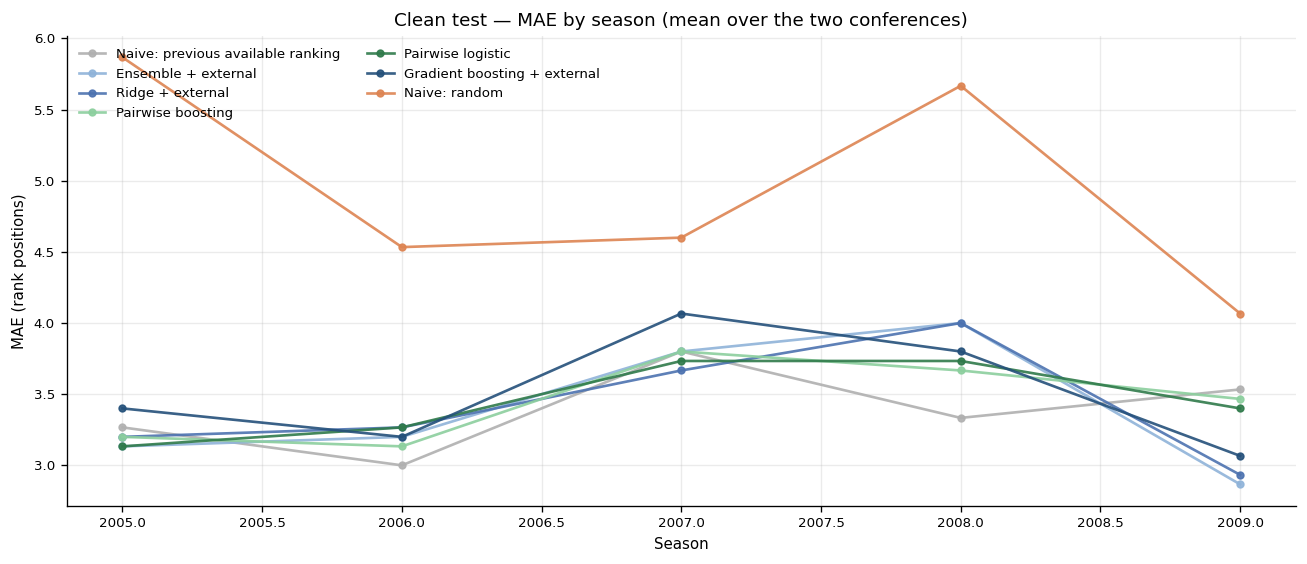

Best model per season:
year
2005                    Pairwise logistic
2006    Naive: previous available ranking
2007                     Ridge + external
2008    Naive: previous available ranking
2009                  Ensemble + external

Number of seasons won:
Naive: previous available ranking    2
Pairwise logistic                    1
Ridge + external                     1
Ensemble + external                  1


In [3]:
season_mae = (
    metrics[metrics["split"] == "clean"]
    .groupby(["year", "model"])["mae"].mean()
    .unstack()
    .reindex(columns=CLEAN_ORDER)
)

fig, ax = plt.subplots(figsize=(11, 4.8))
for model in CLEAN_ORDER:
    ax.plot(season_mae.index, season_mae[model], marker="o", ms=4,
            color=MODEL_COLOR[model], lw=1.6, alpha=0.9, label=model)
ax.set_xlabel("Season")
ax.set_ylabel("MAE (rank positions)")
ax.set_title("Clean test — MAE by season (mean over the two conferences)")
ax.legend(ncol=2, loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

winners = season_mae.idxmin(axis=1)
print("Best model per season:")
print(winners.to_string())
print("\nNumber of seasons won:")
print(winners.value_counts().to_string())

## 3. Error distribution and calibration

The mean error hides the shape of the mistakes. Boxplots show the distribution of the absolute rank
error over all clean-test teams. The table adds calibration statistics: how often the model is within
1, 2 or 3 positions, and the 90th percentile of the error.

C:\Users\barcl\AppData\Local\Temp\ipykernel_29752\2849326985.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, vert=False, labels=CLEAN_ORDER, patch_artist=True,


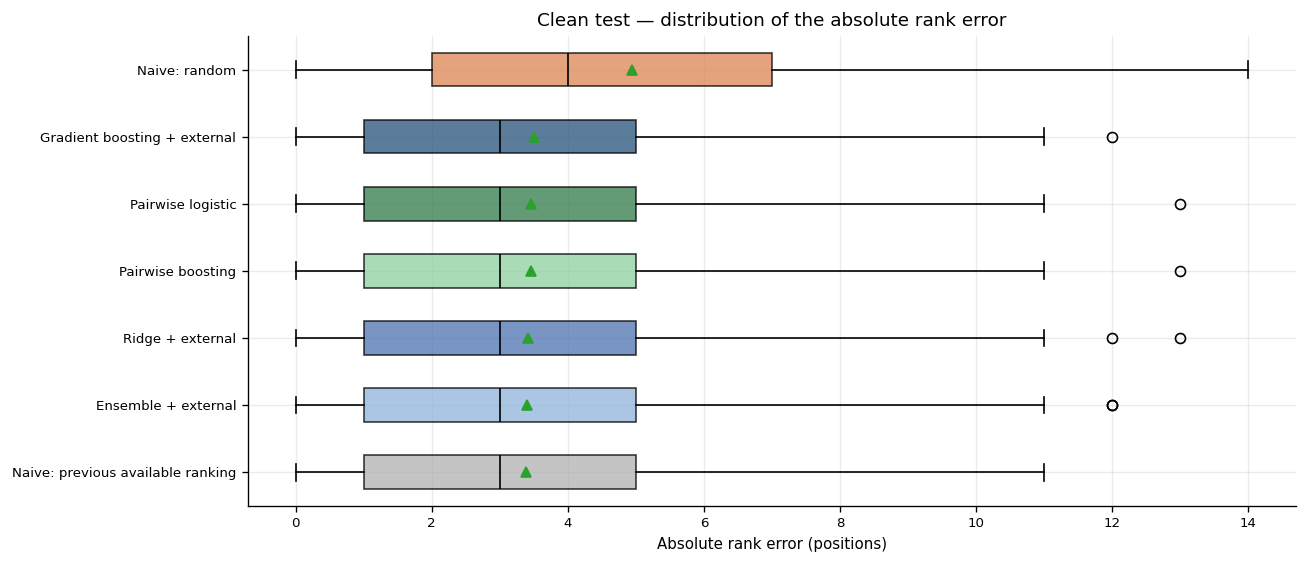

,mean,median,p90,within_1,within_2,within_3,top8_hit
model,,,,,,,
Naive: previous available ranking,3.39,3.0,7.0,32%,45%,62%,64%
Ensemble + external,3.40,3.0,7.0,33%,45%,55%,63%
Ridge + external,3.41,3.0,8.0,35%,46%,59%,60%
Pairwise boosting,3.45,3.0,8.0,30%,49%,61%,59%
Pairwise logistic,3.45,3.0,8.0,32%,49%,59%,59%
Gradient boosting + external,3.51,3.0,7.0,29%,44%,55%,63%
Naive: random,4.95,4.0,10.1,19%,35%,42%,54%


In [4]:
clean_pred = predictions[predictions["split"] == "clean"]
box_data = [clean_pred.loc[clean_pred["model"] == m, "abs_err"].to_numpy() for m in CLEAN_ORDER]

fig, ax = plt.subplots(figsize=(11, 4.8))
bp = ax.boxplot(box_data, vert=False, labels=CLEAN_ORDER, patch_artist=True,
                showmeans=True, meanline=False,
                medianprops={"color": "black", "lw": 1.0})
for patch, model in zip(bp["boxes"], CLEAN_ORDER):
    patch.set_facecolor(MODEL_COLOR[model])
    patch.set_alpha(0.75)
ax.set_xlabel("Absolute rank error (positions)")
ax.set_title("Clean test — distribution of the absolute rank error")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

calibration = clean_pred.groupby("model")["abs_err"].agg(
    mean="mean", median="median", p90=lambda s: s.quantile(0.90)
).reindex(CLEAN_ORDER)
calibration["within_1"] = clean_pred.groupby("model")["abs_err"].apply(lambda s: (s <= 1).mean())
calibration["within_2"] = clean_pred.groupby("model")["abs_err"].apply(lambda s: (s <= 2).mean())
calibration["within_3"] = clean_pred.groupby("model")["abs_err"].apply(lambda s: (s <= 3).mean())
calibration["top8_hit"] = summary[summary["split"] == "clean"].set_index("model")["top_overlap"].reindex(CLEAN_ORDER)
display(
    calibration.style.format({
        "mean": "{:.2f}", "median": "{:.1f}", "p90": "{:.1f}",
        "within_1": "{:.0%}", "within_2": "{:.0%}", "within_3": "{:.0%}",
        "top8_hit": "{:.0%}",
    })
)

## 4. Detailed example

One concrete conference ranking makes the errors interpretable. The table shows the best clean model
on the 2009 Eastern conference: actual rank, predicted rank, signed error (positive = predicted too
low) and absolute error. The scatter plot repeats this for both conferences of the same season; points
close to the diagonal are well ranked.


Naive: previous available ranking — 2009 EC


,actual,tmID,predicted,error,|error|
0,1,WAS,2,1,1
1,2,NJD,3,1,1
2,3,PIT,5,2,2
3,4,BUF,10,6,6
4,5,OTT,11,6,6
5,6,BOS,1,-5,5
6,7,PHI,4,-3,3
7,8,MTL,9,1,1
8,9,NYR,7,-2,2
9,10,ATL,13,3,3



Naive: previous available ranking — 2009 WC


,actual,tmID,predicted,error,|error|
0,1,SJS,1,0,0
1,2,CHI,3,1,1
2,3,PHO,14,11,11
3,4,VAN,4,0,0
4,5,DET,2,-3,3
5,6,LAK,13,7,7
6,7,NAS,10,3,3
7,8,COL,15,7,7
8,9,CAL,5,-4,4
9,10,STL,7,-3,3


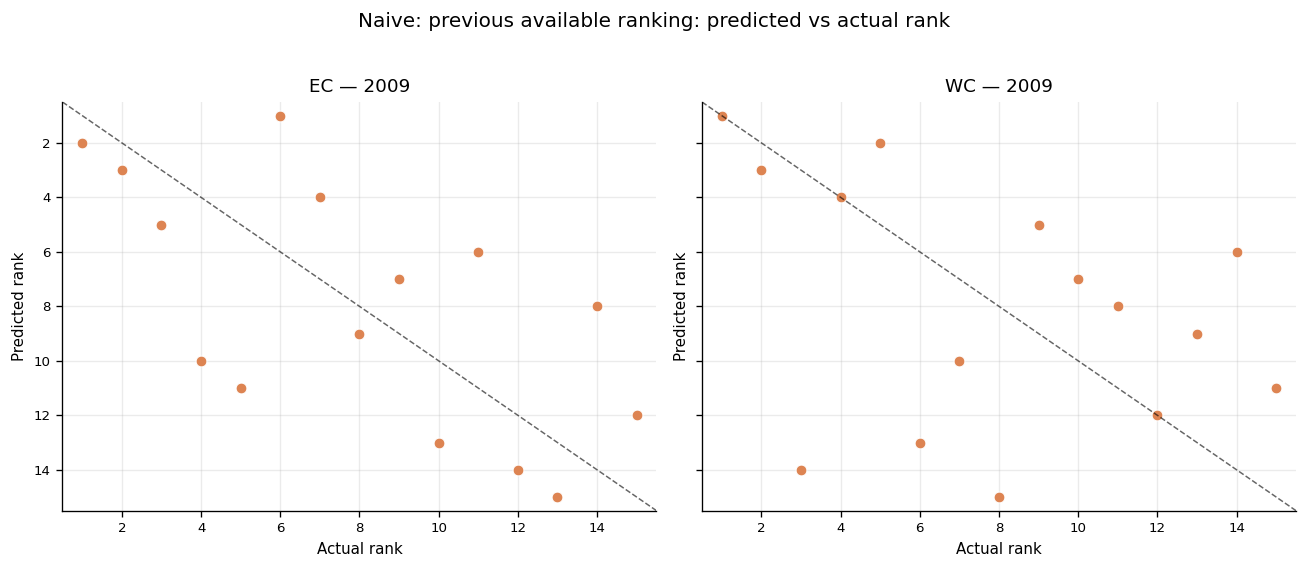

In [5]:
best_clean_model = clean_leaderboard.iloc[0]["model"]
example_year = int(clean_pred["year"].max())

for conf in ["EC", "WC"]:
    g = clean_pred[(clean_pred["model"] == best_clean_model) &
                   (clean_pred["year"] == example_year) &
                   (clean_pred["confID"] == conf)].sort_values("conf_rank")
    print(f"\n{best_clean_model} — {example_year} {conf}")
    display(
        g[["conf_rank", "tmID", "pred_rank", "err", "abs_err"]]
        .rename(columns={"conf_rank": "actual", "pred_rank": "predicted",
                         "err": "error", "abs_err": "|error|"})
        .reset_index(drop=True)
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, conf in zip(axes, ["EC", "WC"]):
    g = clean_pred[(clean_pred["model"] == best_clean_model) &
                   (clean_pred["year"] == example_year) &
                   (clean_pred["confID"] == conf)]
    ax.scatter(g["conf_rank"], g["pred_rank"], s=42,
               color=COLORS[FAMILY[best_clean_model]],
               edgecolor="white", linewidth=0.6, zorder=2)
    limit = g["conf_size"].max() + 0.5
    ax.plot([0.5, limit], [0.5, limit], "k--", lw=0.9, alpha=0.6)
    ax.set_xlim(0.5, limit)
    ax.set_ylim(limit, 0.5)
    ax.set_xlabel("Actual rank")
    ax.set_ylabel("Predicted rank")
    ax.set_title(f"{conf} — {example_year}")
    ax.grid(alpha=0.25)
fig.suptitle(f"{best_clean_model}: predicted vs actual rank", y=1.02)
plt.tight_layout()
plt.show()

## 5. Clean test vs extended backtest

The clean test is short (5 seasons, 10 rankings). The extended backtest (1995–2009, 28 rankings)
increases the sample and checks that the ranking of models is not an artefact of the clean period.
It is **not** a clean out-of-sample test for feature selection, because 1995–2004 was used to select
the features. It is a stability/power check.

split,backtest,clean,Δ (backtest - clean)
model,,,
Naive: previous available ranking,3.076,3.387,-0.310293
Ensemble + external,2.977,3.400,-0.423234
Ridge + external,2.897,3.413,-0.516106
Pairwise boosting,3.014,3.453,-0.438864
Pairwise logistic,2.994,3.453,-0.459717
Gradient boosting + external,3.068,3.507,-0.438718
Naive: random,5.047,4.947,0.100298


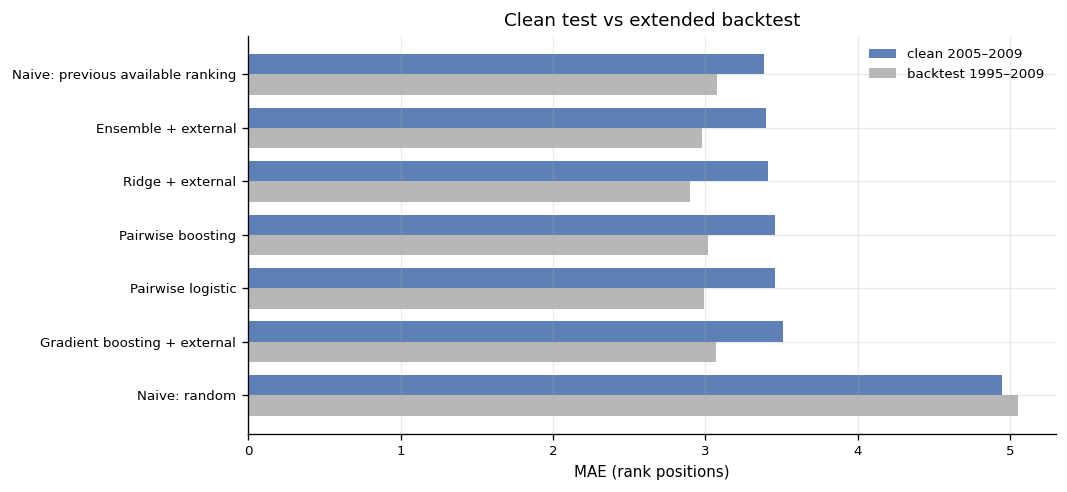

Backtest leaderboard:


In [6]:
comparison = summary.pivot(index="model", columns="split", values="mae")
comparison = comparison.loc[comparison["clean"].sort_values().index]
comparison["Δ (backtest - clean)"] = comparison["backtest"] - comparison["clean"]
display(comparison.style.format("{:+.3f}").format({"clean": "{:.3f}", "backtest": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(comparison))
width = 0.38
ax.barh(x - width / 2, comparison["clean"], height=width, label="clean 2005–2009",
        color="#4C72B0", alpha=0.9)
ax.barh(x + width / 2, comparison["backtest"], height=width, label="backtest 1995–2009",
        color="#B0B0B0", alpha=0.9)
ax.set_yticks(x)
ax.set_yticklabels(comparison.index)
ax.invert_yaxis()
ax.set_xlabel("MAE (rank positions)")
ax.set_title("Clean test vs extended backtest")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print("Backtest leaderboard:")
bt = backtest_leaderboard.copy()
bt["95% CI"] = bt.apply(lambda r: f"[{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]", axis=1)
bt["significant"] = bt["significant"].map({True: "yes", False: "no"})
display(
    bt[["family", "model", "mae", "gain_vs_naive", "95% CI", "significant"]]
    .set_index(["family", "model"])
    .style.format(format_lb)
)

**Interpretation.** If the same models are at the top in both splits, the conclusion is robust. A
large change in the ordering would mean that the clean-test ranking is mostly noise: with 10
conference rankings, one lucky season can move a model by several tenths of a position.

## 6. Models head to head

The leaderboard compares every model to the naive baseline. This section compares the models
directly: positive gain = row model better than column model. The matrix is computed with the same
paired bootstrap, so a value is marked `*` only when the whole interval is above zero.

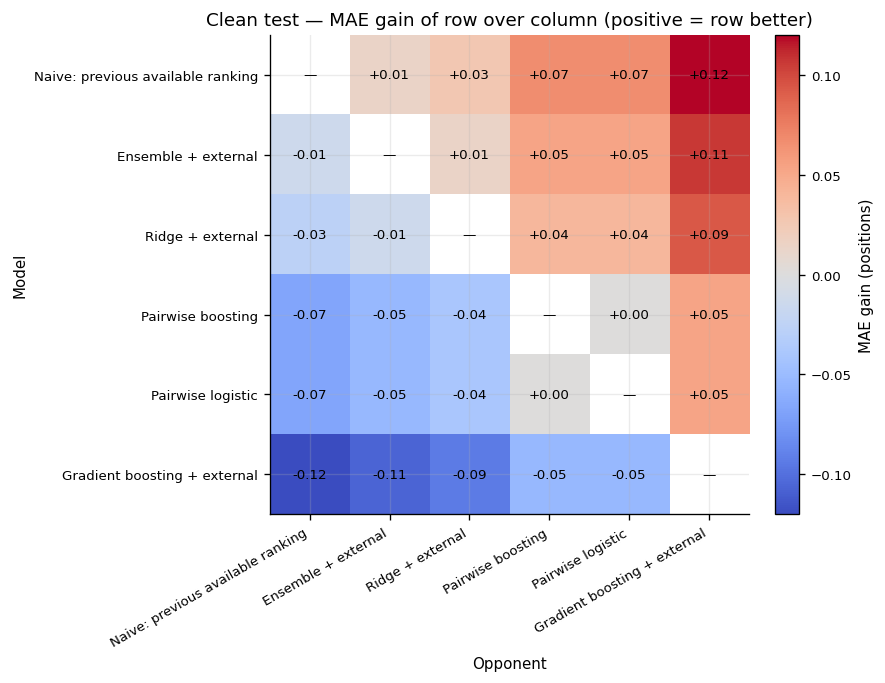

best model vs naive              +0.000 [+0.000, +0.000] -> within noise
best model vs best pairwise      +0.067 [-0.147, +0.307] -> within noise
best external vs best pairwise   +0.053 [-0.240, +0.320] -> within noise


In [7]:
def bootstrap_between(split, model_a, model_b):
    base = model_frame(split, model_b)
    other = model_frame(split, model_a).reindex(base.index)
    groups = (base["confID"] + "-" + base.index.get_level_values("year").astype(str)).to_numpy()
    gain, (low, high) = ru.paired_bootstrap(base["abs_err"], other["abs_err"], groups)
    return gain, low, high


h2h_models = [m for m in CLEAN_ORDER if m != RANDOM]
matrix = pd.DataFrame(np.nan, index=h2h_models, columns=h2h_models)
annotations = pd.DataFrame("", index=h2h_models, columns=h2h_models)
records = []

for a in h2h_models:
    for b in h2h_models:
        if a == b:
            continue
        gain, low, high = bootstrap_between("clean", a, b)
        matrix.loc[a, b] = gain
        annotations.loc[a, b] = f"{gain:+.2f}" + ("*" if low > 0 else "")
        records.append({"model": a, "opponent": b, "gain": gain,
                        "ci_low": low, "ci_high": high, "significant": low > 0})

head_to_head = pd.DataFrame(records)
fig, ax = plt.subplots(figsize=(7.6, 5.8))
vmax = np.nanmax(np.abs(matrix.to_numpy()))
im = ax.imshow(matrix.to_numpy(), cmap="coolwarm", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(h2h_models)))
ax.set_xticklabels(h2h_models, rotation=30, ha="right")
ax.set_yticks(range(len(h2h_models)))
ax.set_yticklabels(h2h_models)
for i in range(len(h2h_models)):
    for j in range(len(h2h_models)):
        text = "—" if i == j else annotations.iloc[i, j]
        ax.text(j, i, text, ha="center", va="center", fontsize=8)
ax.set_title("Clean test — MAE gain of row over column (positive = row better)")
ax.set_xlabel("Opponent")
ax.set_ylabel("Model")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="MAE gain (positions)")
plt.tight_layout()
plt.show()

compare_keys = [
    (clean_leaderboard.iloc[0]["model"], NAIVE, "best model vs naive"),
    (clean_leaderboard.iloc[0]["model"], clean_leaderboard[clean_leaderboard["family"] == "Pairwise"].iloc[0]["model"],
     "best model vs best pairwise"),
    (clean_leaderboard[clean_leaderboard["family"] == "External"].iloc[0]["model"],
     clean_leaderboard[clean_leaderboard["family"] == "Pairwise"].iloc[0]["model"],
     "best external vs best pairwise"),
]
for a, b, label in compare_keys:
    gain, low, high = bootstrap_between("clean", a, b)
    verdict = "significant" if low > 0 else "within noise"
    print(f"{label:32s} {gain:+.3f} [{low:+.3f}, {high:+.3f}] -> {verdict}")

## 7. Verdict

The cells above produce the numbers; this section turns them into a short recommendation.

In [8]:
best_clean = clean_leaderboard.iloc[0]
best_backtest = backtest_leaderboard.iloc[0]
best_external = clean_leaderboard[clean_leaderboard["family"] == "External"].iloc[0]
best_pairwise = clean_leaderboard[clean_leaderboard["family"] == "Pairwise"].iloc[0]
best_non_naive = clean_leaderboard[clean_leaderboard["family"] != "Naive"].iloc[0]
best_per_season = season_mae.idxmin(axis=1)

gain_naive, low_naive, high_naive = bootstrap_against("clean", best_clean["model"])
gain_best_non_naive, low_best_non_naive, high_best_non_naive = bootstrap_against(
    "clean", best_non_naive["model"]
)
gain_ext_pair, low_ext_pair, high_ext_pair = bootstrap_between(
    "clean", best_external["model"], best_pairwise["model"]
)

print("CLEAN TEST (2005–2009, 10 conference rankings)")
print(f"  Best model: {best_clean['model']} ({best_clean['family']})")
print(f"  MAE {best_clean['mae']:.3f} | gain vs previous available ranking "
      f"{gain_naive:+.3f} [{low_naive:+.3f}, {high_naive:+.3f}]")
print(f"  Best trained model: {best_non_naive['model']} ({best_non_naive['family']}) | "
      f"gain vs naive {gain_best_non_naive:+.3f} "
      f"[{low_best_non_naive:+.3f}, {high_best_non_naive:+.3f}] -> "
      f"{'significant' if low_best_non_naive > 0 else 'within noise'}")
print(f"  Best external vs best pairwise: {gain_ext_pair:+.3f} "
      f"[{low_ext_pair:+.3f}, {high_ext_pair:+.3f}] -> "
      f"{'significant' if low_ext_pair > 0 else 'within noise'}")
print(f"  Seasons won: {dict(best_per_season.value_counts())}")

print("\nBACKTEST (1995–2009, 28 conference rankings)")
print(f"  Best model: {best_backtest['model']} ({best_backtest['family']}) | "
      f"MAE {best_backtest['mae']:.3f} | gain vs naive "
      f"{best_backtest['gain_vs_naive']:+.3f} "
      f"[{best_backtest['ci_low']:+.3f}, {best_backtest['ci_high']:+.3f}]")

external_names = [m for m in CLEAN_ORDER if FAMILY[m] == "External"]
pairwise_names = [m for m in CLEAN_ORDER if FAMILY[m] == "Pairwise"]
print("\nMODEL FAMILIES")
print(f"  External models on clean test: " +
      ", ".join(f"{m} ({summary[(summary['split'] == 'clean') & (summary['model'] == m)]['mae'].iloc[0]:.3f})"
                for m in external_names))
print(f"  Pairwise models on clean test: " +
      ", ".join(f"{m} ({summary[(summary['split'] == 'clean') & (summary['model'] == m)]['mae'].iloc[0]:.3f})"
                for m in pairwise_names))

print("\nRECOMMENDATION")
if low_best_non_naive > 0:
    print(f"  * Keep {best_non_naive['model']}: it is reliably better than the naive baseline on the")
    print("    clean test. The extra complexity is justified.")
else:
    print("  * On the clean test, no trained model is reliably better than previous available ranking.")
    print("    Keep the naive baseline as the reference, and treat the external models as a small,")
    print("    uncertain improvement rather than a clear win.")
print(f"  * On the extended backtest, the best model is {best_backtest['model']} "
      f"(MAE {best_backtest['mae']:.3f}).")
print("  * Pairwise models are competitive but do not add enough to justify the extra complexity here.")
print("  * The analysis is leak-free: no coach column and no current-season roster composition.")

CLEAN TEST (2005–2009, 10 conference rankings)
  Best model: Naive: previous available ranking (Naive)
  MAE 3.387 | gain vs previous available ranking +0.000 [+0.000, +0.000]
  Best trained model: Ensemble + external (External) | gain vs naive -0.013 [-0.467, +0.347] -> within noise
  Best external vs best pairwise: +0.053 [-0.240, +0.320] -> within noise
  Seasons won: {'Naive: previous available ranking': np.int64(2), 'Pairwise logistic': np.int64(1), 'Ridge + external': np.int64(1), 'Ensemble + external': np.int64(1)}

BACKTEST (1995–2009, 28 conference rankings)
  Best model: Ridge + external (External) | MAE 2.897 | gain vs naive +0.179 [-0.010, +0.348]

MODEL FAMILIES
  External models on clean test: Ensemble + external (3.400), Ridge + external (3.413), Gradient boosting + external (3.507)
  Pairwise models on clean test: Pairwise boosting (3.453), Pairwise logistic (3.453)

RECOMMENDATION
  * On the clean test, no trained model is reliably better than previous available rankin

## 8. Notes and limitations

* **Sample size.** The clean test has 5 seasons and 10 conference rankings. The paired bootstrap over
  whole rankings is the right unit, but intervals remain wide. Differences of a few hundredths of a
  position are not meaningful.
* **Naive baseline.** “Previous available ranking” is last season's points percentage re-ranked in
  the current conference; teams without history receive the league-average score. It is a strong
  baseline because hockey standings are persistent.
* **Points percentage.** The target is ``Pts / (2 * GP)``, not raw points or wins, so shortened and
  normal seasons are comparable. This changes the numbers slightly compared with a raw-points
  analysis but not the ranking of teams inside a normal season.
* **Leak policy.** No coach column and no current-season roster composition is used. Every
  team-performance feature is lagged (season *Y-1* predicts *Y*). This is why the external gain is
  smaller than in a naive roster-based analysis: the model only sees pre-season information.
* **Backtest.** 1995–2004 was used for feature selection, so the extended backtest is a
  stability/power check, not a fully clean out-of-sample test.
* **What is not available.** Market information (preseason win totals, injuries, payroll) and
  game-level data (current win streak) are not in the provided tables. They are the next real lever
  for a larger gain.
* **Reproducibility.** Re-run `ranking_predictions.ipynb` to refresh the result files, then
  `ranking_results_analysis.ipynb` to refresh this analysis. The analysis notebook does not train
  anything, so it is fast and safe to re-run.